In [207]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [208]:
df=pd.read_csv("insurance.csv")

In [209]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [210]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [211]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [212]:
df["smoker"].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [213]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

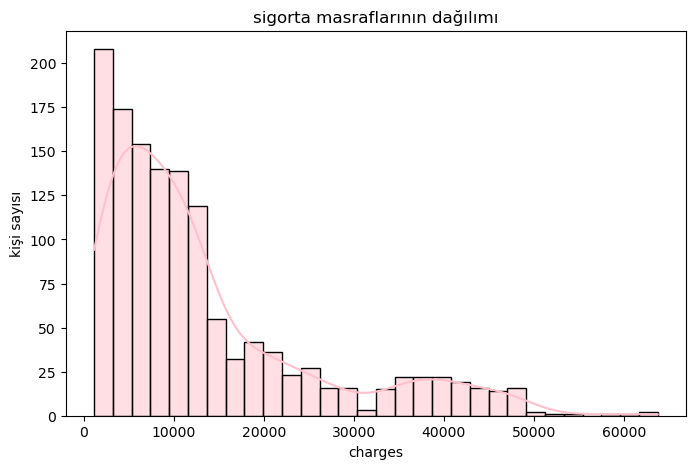

In [214]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="charges",kde=True,color="pink")
plt.title("sigorta masraflarının dağılımı")
plt.xlabel("charges")
plt.ylabel("kişi sayısı")
plt.show()

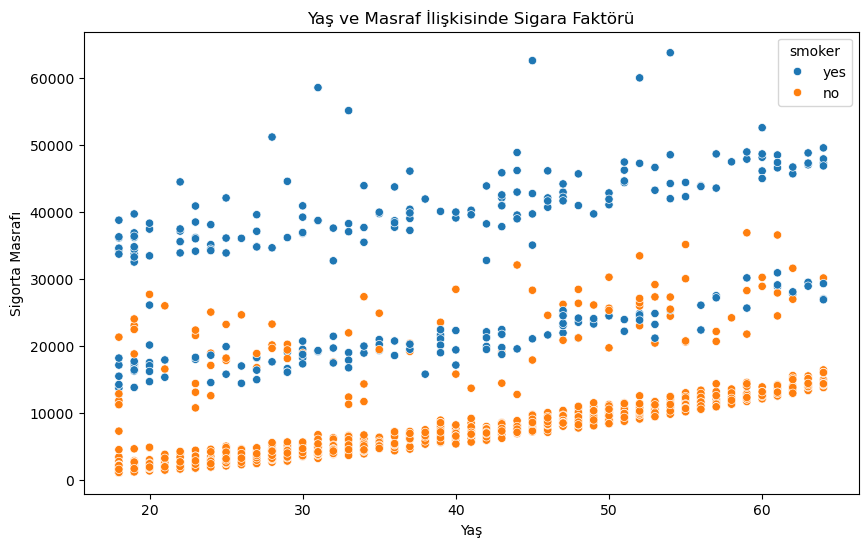

In [215]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="age",y="charges",hue="smoker")
plt.title('Yaş ve Masraf İlişkisinde Sigara Faktörü')
plt.xlabel('Yaş')
plt.ylabel('Sigorta Masrafı')
plt.show()

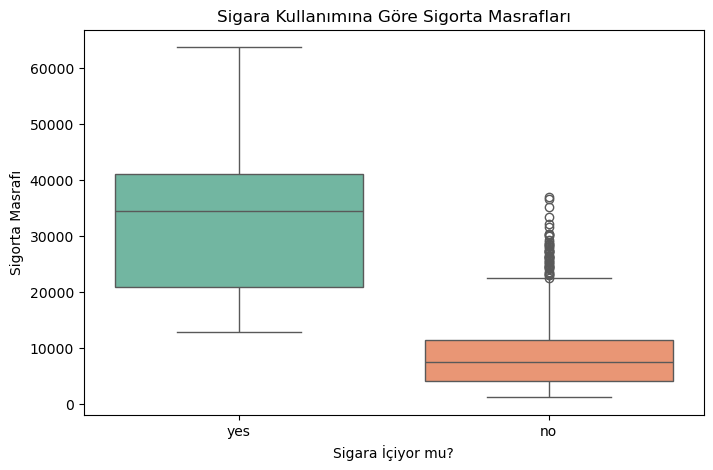

In [216]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='smoker', y='charges', palette='Set2')
plt.title('Sigara Kullanımına Göre Sigorta Masrafları')
plt.xlabel('Sigara İçiyor mu?')
plt.ylabel('Sigorta Masrafı')
plt.show()

In [217]:
from sklearn.model_selection import train_test_split

In [218]:
X=df.drop("charges",axis=1)
y=df["charges"]

In [219]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [220]:
for col in ["smoker","sex"]:
    X_train[col] = label_encoder.fit_transform(X_train[col])
    X_test[col] = label_encoder.transform(X_test[col])

In [221]:
X_train=pd.get_dummies(X_train,columns=["region"],drop_first=True)
X_test=pd.get_dummies(X_test,columns=["region"],drop_first=True)

In [222]:
X_train.corr()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
age,1.000000,-0.008459,0.118274,0.060999,-0.052035,0.013019,-0.015068,0.022307
sex,-0.008459,1.000000,0.015293,0.017080,0.070908,0.017047,-0.008217,-0.013911
bmi,0.118274,0.015293,1.000000,-0.005040,-0.003450,-0.112666,0.247317,0.010248
children,0.060999,0.017080,-0.005040,1.000000,0.013994,0.033319,-0.025133,-0.002450
smoker,-0.052035,0.070908,-0.003450,0.013994,1.000000,-0.030547,0.051450,-0.033688
region_northwest,0.013019,0.017047,-0.112666,0.033319,-0.030547,1.000000,-0.336290,-0.320954
region_southeast,-0.015068,-0.008217,0.247317,-0.025133,0.051450,-0.336290,1.000000,-0.343194
region_southwest,0.022307,-0.013911,0.010248,-0.002450,-0.033688,-0.320954,-0.343194,1.000000


In [223]:
from sklearn.tree import DecisionTreeRegressor

In [224]:
dectree=DecisionTreeRegressor()

In [225]:
dectree.fit(X_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [226]:
y_pred=dectree.predict(X_test)

In [227]:
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score


In [228]:
print(mean_squared_error(y_pred,y_test))
print(mean_absolute_error(y_pred,y_test))
print(r2_score(y_test,y_pred))

46235835.54146586
3387.0691574477614
0.7021822008000377


In [229]:
param = {
    "criterion" : ["squared_error", "absolute_error", "poisson"],
    "splitter" : ["best", "random"],
    "max_depth" : [1,2,3,4,5,15,None],
    "min_samples_split" : [2,5,10,20]
}

In [230]:
from sklearn.model_selection import GridSearchCV

In [231]:
grid = GridSearchCV(estimator = DecisionTreeRegressor(), param_grid=param, cv=5)

In [232]:
import warnings
warnings.filterwarnings("ignore")
grid.fit(X_train,y_train)

,estimator,DecisionTreeRegressor()
,param_grid,"{'criterion': ['squared_error', 'absolute_error', ...], 'max_depth': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'splitter': ['best', 'random']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'absolute_error'


In [233]:
grid.best_params_

{'criterion': 'absolute_error',
 'max_depth': 5,
 'min_samples_split': 20,
 'splitter': 'best'}

In [234]:
y_pred = grid.predict(X_test)

In [235]:
print(mean_squared_error(y_pred,y_test))
print(mean_absolute_error(y_pred,y_test))
print(r2_score(y_test,y_pred))

21755106.568096142
1953.658552011194
0.8598693441224741


In [260]:

from sklearn.preprocessing import StandardScaler

In [261]:
from sklearn.linear_model import LinearRegression

In [262]:
scaler=StandardScaler()

In [263]:
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [264]:
lin_reg=LinearRegression()

In [265]:
lin_reg.fit(X_train_scaled,y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [266]:
y_pred2=lin_reg.predict(X_test_scaled)

In [267]:
print(mean_squared_error(y_pred2,y_test))
print(mean_absolute_error(y_pred2,y_test))
print(r2_score(y_test,y_pred2))

33596915.851361476
4181.194473753651
0.7835929767120722
